# Lab 6 — Language Identification: Classical + Neural Classifiers vs. FastText Supervised

Reuses the **23-language Indian-language identification dataset built in
Assignment 1** (`Lab1/data/{train,val,test}.csv` — IndicCorp-derived
paragraphs, ~800/100/100 examples per language, 18,400 / 2,300 / 2,300 rows).

Classifiers compared, all evaluated with a **hand-rolled macro-F1**
(confusion matrix + per-class precision/recall/F1, no `sklearn.metrics`
anywhere in this notebook):

1. **Logistic regression** on averaged FastText wiki word vectors
2. **MLP** with `n = 0, 1, 2` hidden layers on the same averaged vectors
   (`n=0` is algebraically identical to plain logistic regression — a
   built-in sanity check)
3. **LSTM** over a frozen FastText-wiki embedding lookup
4. **GRU** over the same frozen embedding lookup
5. **FastText supervised** ([fasttext.cc supervised tutorial](https://fasttext.cc/docs/en/supervised-tutorial.html)) —
   trains its own subword n-gram embeddings from scratch, via the official
   `fasttext` library

Pretrained vectors: [FastText Wikipedia word vectors](https://fasttext.cc/docs/en/pretrained-vectors.html)
(`wiki.<lang>.vec`, 300-d). Of the 23 dataset languages, **18 have a
pretrained wiki vector file; 5 do not** (Bodo `brx`, Dogri `doi`, Khasi,
Manipuri/Meitei `mni`, Santali) — those 5 fall back on whatever their
tokens happen to share with other languages' vectors (mostly Devanagari
function words), which is tracked explicitly as a coverage diagnostic
below rather than swept under the rug.


## 0. Setup

In [1]:
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                 "torch", "fasttext", "numpy", "pandas", "matplotlib", "requests"])


CompletedProcess(args=['/home/deeraj/miniconda3/bin/python3.13', '-m', 'pip', 'install', '-q', 'torch', 'fasttext', 'numpy', 'pandas', 'matplotlib', 'requests'], returncode=0)

In [2]:
import json
import random
import re
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

DATA_DIR = "../Lab1/data"     # Assignment 1 dataset
OUT_DIR = "data"              # this lab's outputs
DIM = 300
MAX_LEN = 64
BATCH_SIZE = 64


device: cuda


## 1. Load the Assignment 1 dataset

In [3]:
train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")
with open(f"{DATA_DIR}/languages.json", encoding="utf-8") as f:
    labels = json.load(f)
label2idx = {l: i for i, l in enumerate(labels)}
idx2label = {i: l for i, l in enumerate(labels)}

print(f"train={len(train_df)}  val={len(val_df)}  test={len(test_df)}  classes={len(labels)}")
train_df.groupby("label").size().rename("n_train").to_frame().T


train=18400  val=2300  test=2300  classes=23


label,asm_Beng,ben_Beng,brx_Deva,doi_Deva,gom_Deva,guj_Gujr,hin_Deva,kan_Knda,kas_Arab,khasi,...,mni_Mtei,npi_Deva,ory_Orya,pan_Guru,san_Deva,santhali,snd_Deva,tam_Taml,tel_Telu,urd_Arab
n_train,800,800,800,800,800,800,800,800,800,800,...,800,800,800,800,800,800,800,800,800,800


## 2. Tokenization & vocabulary

A simple Unicode word tokenizer (`\w+` minus digits/underscore, lowercased)
is used everywhere in this notebook, so every classifier — including the
FastText-supervised one — sees the same token stream.

The vocabulary below is the **union of tokens across train+val+test**. This
is only used to decide which rows of the huge pretrained `.vec` files are
worth keeping; no label information is touched, so it is not leakage.

In [4]:
TOKEN_RE = re.compile(r"[^\W\d_]+", re.UNICODE)


def tokenize(text: str):
    return TOKEN_RE.findall(str(text).lower())


vocab_counts = Counter()
for df in (train_df, val_df, test_df):
    for text in df["text"]:
        vocab_counts.update(tokenize(text))

vocab = set(vocab_counts.keys())
print("dataset vocabulary size:", len(vocab))


dataset vocabulary size:

 42834


## 3. Stream-filter the FastText wiki vectors

The 18 relevant `wiki.<lang>.vec` files sum to **~4.7 GB**, and the disk
here does not have room to keep them. Instead each file is read as an HTTP
stream and filtered line-by-line, keeping only rows whose word is in our
dataset vocabulary — the raw file is never written to disk.

**One shared `word -> vector` table is built across all 18 languages**
(first language to define a word wins on a collision). This is required:
at inference time the model does not know the true language, so a
per-language table keyed by the gold label would leak the answer. Devanagari
function words legitimately collide across hin/mar/npi/san/mai/gom/snd —
that's expected, not a bug.

In [5]:
BASE_URL = "https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.{code}.vec"

# dataset label -> fasttext wiki language code (None = no pretrained vectors exist)
LANG_TO_FASTTEXT = {
    "asm_Beng": "as", "ben_Beng": "bn", "brx_Deva": None, "doi_Deva": None,
    "gom_Deva": "gom", "guj_Gujr": "gu", "hin_Deva": "hi", "kan_Knda": "kn",
    "kas_Arab": "ks", "khasi": None, "mai_Deva": "mai", "mal_Mlym": "ml",
    "mar_Deva": "mr", "mni_Mtei": None, "npi_Deva": "ne", "ory_Orya": "or",
    "pan_Guru": "pa", "san_Deva": "sa", "santhali": None, "snd_Deva": "sd",
    "tam_Taml": "ta", "tel_Telu": "te", "urd_Arab": "ur",
}
missing = sorted({l for l, c in LANG_TO_FASTTEXT.items() if c is None})
print("languages with NO pretrained wiki vectors:", missing)


def stream_filter(code, vocab, word_to_vec):
    url = BASE_URL.format(code=code)
    t0 = time.time()
    n_lines = n_kept = 0
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        first = True
        for raw_line in r.iter_lines(chunk_size=1 << 20):
            if not raw_line:
                continue
            n_lines += 1
            if first:
                first = False
                continue  # header: "<n_words> <dim>"
            line = raw_line.decode("utf-8", errors="ignore")
            sp = line.find(" ")
            if sp == -1:
                continue
            word = line[:sp]
            if word in vocab and word not in word_to_vec:
                parts = line[sp + 1:].split(" ")
                if len(parts) >= DIM:
                    try:
                        vec = np.asarray(parts[:DIM], dtype=np.float32)
                    except ValueError:
                        continue
                    word_to_vec[word] = vec
                    n_kept += 1
    print(f"  [{code}] scanned {n_lines} lines, kept {n_kept}, {time.time()-t0:.1f}s")


languages with NO pretrained wiki vectors: ['brx_Deva', 'doi_Deva', 'khasi', 'mni_Mtei', 'santhali']


In [6]:
import os

cache_path = f"{OUT_DIR}/fasttext_filtered.npz"
if os.path.exists(cache_path):
    print("loading cached filtered vectors from", cache_path)
    npz = np.load(cache_path, allow_pickle=True)
    words, mat = list(npz["words"]), npz["vectors"].astype(np.float32)
    word2vec = {w: mat[i] for i, w in enumerate(words)}
else:
    word2vec = {}
    done_codes = set()
    for label, code_ in LANG_TO_FASTTEXT.items():
        if code_ is not None and code_ not in done_codes:
            stream_filter(code_, vocab, word2vec)
            done_codes.add(code_)
    words = sorted(word2vec.keys())
    mat = np.stack([word2vec[w] for w in words]).astype(np.float32)
    np.savez_compressed(cache_path, words=np.array(words, dtype=object), vectors=mat)

print(f"merged embedding table: {len(words)} words x {mat.shape[1]}-d")


loading cached filtered vectors from data/fasttext_filtered.npz


merged embedding table: 19323 words x 300-d


### Coverage diagnostic

Before training anything: what fraction of each language's tokens actually
have a vector in the merged table? This is the number that will explain
most of the downstream results for the embedding-based models.

In [7]:
def coverage_report(df, word2vec, labels):
    rows = {}
    for lab in labels:
        sub = df[df["label"] == lab]
        n_tok = n_hit = n_fully_oov = 0
        for text in sub["text"]:
            toks = tokenize(text)
            hits = sum(1 for t in toks if t in word2vec)
            n_tok += len(toks)
            n_hit += hits
            if toks and hits == 0:
                n_fully_oov += 1
        rows[lab] = {
            "n_sentences": int(len(sub)),
            "token_coverage": (n_hit / n_tok) if n_tok else 0.0,
            "pct_sentences_fully_oov": (n_fully_oov / len(sub)) if len(sub) else 0.0,
        }
    return rows


all_df = pd.concat([train_df, val_df, test_df])
coverage = coverage_report(all_df, word2vec, labels)
cov_df = pd.DataFrame(coverage).T.sort_values("token_coverage")
cov_df["token_coverage"] = (cov_df["token_coverage"] * 100).round(1)
cov_df["pct_sentences_fully_oov"] = (cov_df["pct_sentences_fully_oov"] * 100).round(1)
with open(f"{OUT_DIR}/coverage_report.json", "w", encoding="utf-8") as f:
    json.dump(coverage, f, indent=2, ensure_ascii=False)
cov_df


,n_sentences,token_coverage,pct_sentences_fully_oov
santhali,1000.0,1.7,91.1
mni_Mtei,1000.0,2.7,86.5
kas_Arab,1000.0,80.5,0.0
mal_Mlym,1000.0,83.1,0.0
kan_Knda,1000.0,84.0,0.0
ory_Orya,1000.0,84.8,0.0
guj_Gujr,1000.0,85.8,0.0
tam_Taml,1000.0,86.2,0.1
asm_Beng,1000.0,87.7,0.0
khasi,1000.0,87.7,0.0


## 4.  macro-F1

No `sklearn.metrics` (or any other sklearn class) is used for evaluation
anywhere in this notebook. Macro-F1 = confusion matrix -> per-class
precision/recall/F1 -> unweighted mean of the 23 per-class F1 scores.

In [8]:
def confusion_matrix(y_true, y_pred, labels):
    idx = {l: i for i, l in enumerate(labels)}
    n = len(labels)
    cm = np.zeros((n, n), dtype=np.int64)
    for t, p in zip(y_true, y_pred):
        cm[idx[t], idx[p]] += 1
    return cm


def macro_f1(y_true, y_pred, labels):
    cm = confusion_matrix(y_true, y_pred, labels)
    per_class, f1s = {}, []
    for i, lab in enumerate(labels):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        support = cm[i, :].sum()
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
        per_class[lab] = {"precision": float(precision), "recall": float(recall),
                           "f1": float(f1), "support": int(support)}
        f1s.append(f1)
    return float(np.mean(f1s)), per_class


def accuracy(y_true, y_pred):
    y_true, y_pred = list(y_true), list(y_pred)
    return sum(t == p for t, p in zip(y_true, y_pred)) / len(y_true) if y_true else 0.0


## 5. Classifiers 1–3: averaged word vectors -> logistic regression / MLP

`n_hidden=0` is a single `Linear(300, 23)` layer trained with
cross-entropy — algebraically multinomial logistic regression. `n_hidden=1`
and `n_hidden=2` add ReLU hidden layers of width 128. Sentence features are
the mean of the FastText wiki vectors of the tokens that were found (an
all-OOV sentence falls back to the zero vector).

In [9]:
def sentence_avg_vector(tokens, word2vec):
    vecs = [word2vec[t] for t in tokens if t in word2vec]
    return np.mean(vecs, axis=0).astype(np.float32) if vecs else np.zeros(DIM, dtype=np.float32)


class AvgVecDataset(Dataset):
    def __init__(self, df, word2vec, label2idx):
        self.X = np.stack([sentence_avg_vector(tokenize(t), word2vec) for t in df["text"]])
        self.y = np.array([label2idx[l] for l in df["label"]], dtype=np.int64)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.X[i], self.y[i]


train_avg = AvgVecDataset(train_df, word2vec, label2idx)
val_avg = AvgVecDataset(val_df, word2vec, label2idx)
test_avg = AvgVecDataset(test_df, word2vec, label2idx)
print(train_avg.X.shape, val_avg.X.shape, test_avg.X.shape)


(18400, 300) (2300, 300) (2300, 300)


In [10]:
class LogRegOrMLP(nn.Module):
    # Averaged-word-vector classifier. n_hidden=0 is plain logistic regression.
    def __init__(self, in_dim, n_classes, n_hidden=0, hidden_dim=128, dropout=0.2):
        super().__init__()
        layers, d = [], in_dim
        for _ in range(n_hidden):
            layers += [nn.Linear(d, hidden_dim), nn.ReLU(), nn.Dropout(dropout)]
            d = hidden_dim
        layers.append(nn.Linear(d, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def train_avgvec_model(model, train_ds, val_ds, labels, idx2label, epochs=40, lr=1e-3, patience=5, tag=""):
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    crit = nn.CrossEntropyLoss()
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=256, shuffle=False)

    best_f1, best_state, bad_epochs = -1, None, 0
    for ep in range(1, epochs + 1):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()

        model.eval()
        preds, trues = [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                out = model(xb.to(DEVICE))
                preds += out.argmax(1).cpu().tolist()
                trues += yb.tolist()
        val_f1, _ = macro_f1([idx2label[t] for t in trues], [idx2label[p] for p in preds], labels)
        if val_f1 > best_f1:
            best_f1, best_state, bad_epochs = val_f1, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            bad_epochs += 1
        if ep == 1 or ep % 5 == 0:
            print(f"  [{tag}] epoch {ep:2d}  val_macro_f1={val_f1:.4f}  best={best_f1:.4f}")
        if bad_epochs >= patience:
            print(f"  [{tag}] early stop at epoch {ep}")
            break
    model.load_state_dict(best_state)
    return model, best_f1


def eval_avgvec_model(model, ds, labels, idx2label):
    model.eval()
    loader = DataLoader(ds, batch_size=256, shuffle=False)
    preds, trues = [], []
    with torch.no_grad():
        for xb, yb in loader:
            out = model(xb.to(DEVICE))
            preds += out.argmax(1).cpu().tolist()
            trues += yb.tolist()
    y_pred = [idx2label[p] for p in preds]
    y_true = [idx2label[t] for t in trues]
    f1, per_class = macro_f1(y_true, y_pred, labels)
    return f1, accuracy(y_true, y_pred), per_class


In [11]:
results = {}

for name, n_hidden in [("logreg_avgvec", 0), ("mlp_1hidden_avgvec", 1), ("mlp_2hidden_avgvec", 2)]:
    print(f"\n=== {name} (n_hidden={n_hidden}) ===")
    t0 = time.time()
    model = LogRegOrMLP(in_dim=DIM, n_classes=len(labels), n_hidden=n_hidden, hidden_dim=128)
    model, val_f1 = train_avgvec_model(model, train_avg, val_avg, labels, idx2label, tag=name)
    test_f1, test_acc, per_class = eval_avgvec_model(model, test_avg, labels, idx2label)
    results[name] = {
        "description": f"Averaged FastText wiki vectors -> {'logistic regression' if n_hidden==0 else f'MLP ({n_hidden} hidden layer(s))'}",
        "val_macro_f1": val_f1, "test_macro_f1": test_f1, "test_accuracy": test_acc,
        "per_class_test": per_class, "train_seconds": time.time() - t0,
    }
    print(f"  test_macro_f1={test_f1:.4f}  test_accuracy={test_acc:.4f}")



=== logreg_avgvec (n_hidden=0) ===


  [logreg_avgvec] epoch  1  val_macro_f1=0.6799  best=0.6799


  [logreg_avgvec] epoch  5  val_macro_f1=0.7495  best=0.7495


  [logreg_avgvec] epoch 10  val_macro_f1=0.7651  best=0.7651


  [logreg_avgvec] epoch 15  val_macro_f1=0.7791  best=0.7791


  [logreg_avgvec] epoch 20  val_macro_f1=0.7814  best=0.7845


... (14 outputs left out)

  [mlp_2hidden_avgvec] epoch 20  val_macro_f1=0.8121  best=0.8138


  [mlp_2hidden_avgvec] epoch 25  val_macro_f1=0.8177  best=0.8221


  [mlp_2hidden_avgvec] epoch 30  val_macro_f1=0.8196  best=0.8253


  [mlp_2hidden_avgvec] early stop at epoch 32
  test_macro_f1=0.8254  test_accuracy=0.8343


## 6. Classifiers 4–5: LSTM and GRU over a frozen FastText-wiki embedding

Each token is looked up in the same merged embedding table (`<pad>`=0,
`<unk>`=1 mapped to the zero vector, frozen — not fine-tuned), fed through
an LSTM or GRU, and the final hidden state goes through a linear layer.
Sequences are truncated/padded to `MAX_LEN=64` tokens and packed so the
recurrent layer ignores padding.

In [12]:
def build_seq_vocab(words, mat):
    vocab_size = len(words) + 2
    embed = np.zeros((vocab_size, DIM), dtype=np.float32)
    embed[2:] = mat
    word2idx = {"<pad>": 0, "<unk>": 1}
    for i, w in enumerate(words):
        word2idx[w] = i + 2
    return word2idx, embed


class SeqDataset(Dataset):
    def __init__(self, df, word2idx, label2idx, max_len=MAX_LEN):
        self.seqs, self.lens = [], []
        for t in df["text"]:
            toks = tokenize(t)[:max_len]
            ids = [word2idx.get(tok, 1) for tok in toks] or [1]
            self.lens.append(len(ids))
            ids = ids + [0] * (max_len - len(ids))
            self.seqs.append(ids)
        self.seqs = np.array(self.seqs, dtype=np.int64)
        self.lens = np.array(self.lens, dtype=np.int64)
        self.y = np.array([label2idx[l] for l in df["label"]], dtype=np.int64)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.seqs[i], self.lens[i], self.y[i]


word2idx, embed_mat = build_seq_vocab(words, mat)
train_seq = SeqDataset(train_df, word2idx, label2idx)
val_seq = SeqDataset(val_df, word2idx, label2idx)
test_seq = SeqDataset(test_df, word2idx, label2idx)
print(train_seq.seqs.shape, "embedding table:", embed_mat.shape)


(18400, 64) embedding table: (19325, 300)


In [13]:
class RNNClassifier(nn.Module):
    def __init__(self, embed_weight, n_classes, hidden_dim=128, rnn_type="lstm", dropout=0.2):
        super().__init__()
        vocab_size, dim = embed_weight.shape
        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embed_weight, dtype=torch.float32), freeze=True, padding_idx=0
        )
        rnn_cls = nn.LSTM if rnn_type == "lstm" else nn.GRU
        self.rnn = rnn_cls(input_size=dim, hidden_size=hidden_dim, num_layers=1, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, n_classes)

    def forward(self, x, lengths):
        emb = self.embedding(x)
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        if isinstance(self.rnn, nn.LSTM):
            _, (h_n, _) = self.rnn(packed)
        else:
            _, h_n = self.rnn(packed)
        return self.fc(self.dropout(h_n[-1]))


def train_seq_model(model, train_ds, val_ds, labels, idx2label, epochs=25, lr=1e-3, patience=4, tag=""):
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    crit = nn.CrossEntropyLoss()
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=256, shuffle=False)

    best_f1, best_state, bad_epochs = -1, None, 0
    for ep in range(1, epochs + 1):
        model.train()
        for xb, lb, yb in train_loader:
            xb, lb, yb = xb.to(DEVICE), lb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = crit(model(xb, lb), yb)
            loss.backward()
            opt.step()

        model.eval()
        preds, trues = [], []
        with torch.no_grad():
            for xb, lb, yb in val_loader:
                out = model(xb.to(DEVICE), lb.to(DEVICE))
                preds += out.argmax(1).cpu().tolist()
                trues += yb.tolist()
        val_f1, _ = macro_f1([idx2label[t] for t in trues], [idx2label[p] for p in preds], labels)
        if val_f1 > best_f1:
            best_f1, best_state, bad_epochs = val_f1, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            bad_epochs += 1
        print(f"  [{tag}] epoch {ep:2d}  val_macro_f1={val_f1:.4f}  best={best_f1:.4f}")
        if bad_epochs >= patience:
            print(f"  [{tag}] early stop at epoch {ep}")
            break
    model.load_state_dict(best_state)
    return model, best_f1


def eval_seq_model(model, ds, labels, idx2label):
    model.eval()
    loader = DataLoader(ds, batch_size=256, shuffle=False)
    preds, trues = [], []
    with torch.no_grad():
        for xb, lb, yb in loader:
            out = model(xb.to(DEVICE), lb.to(DEVICE))
            preds += out.argmax(1).cpu().tolist()
            trues += yb.tolist()
    y_pred = [idx2label[p] for p in preds]
    y_true = [idx2label[t] for t in trues]
    f1, per_class = macro_f1(y_true, y_pred, labels)
    return f1, accuracy(y_true, y_pred), per_class


In [14]:
for rnn_type in ["lstm", "gru"]:
    name = f"{rnn_type}_frozen_fasttext"
    print(f"\n=== {name} ===")
    t0 = time.time()
    model = RNNClassifier(embed_mat, n_classes=len(labels), hidden_dim=128, rnn_type=rnn_type)
    model, val_f1 = train_seq_model(model, train_seq, val_seq, labels, idx2label, tag=name)
    test_f1, test_acc, per_class = eval_seq_model(model, test_seq, labels, idx2label)
    results[name] = {
        "description": f"Frozen FastText wiki embeddings -> {rnn_type.upper()} -> linear",
        "val_macro_f1": val_f1, "test_macro_f1": test_f1, "test_accuracy": test_acc,
        "per_class_test": per_class, "train_seconds": time.time() - t0,
    }
    print(f"  test_macro_f1={test_f1:.4f}  test_accuracy={test_acc:.4f}")



=== lstm_frozen_fasttext ===


  [lstm_frozen_fasttext] epoch  1  val_macro_f1=0.7079  best=0.7079


  [lstm_frozen_fasttext] epoch  2  val_macro_f1=0.7835  best=0.7835


  [lstm_frozen_fasttext] epoch  3  val_macro_f1=0.8257  best=0.8257


  [lstm_frozen_fasttext] epoch  4  val_macro_f1=0.8486  best=0.8486


  [lstm_frozen_fasttext] epoch  5  val_macro_f1=0.8563  best=0.8563


... (23 outputs left out)

  [gru_frozen_fasttext] epoch 11  val_macro_f1=0.8577  best=0.8702


  [gru_frozen_fasttext] epoch 12  val_macro_f1=0.8684  best=0.8702


  [gru_frozen_fasttext] epoch 13  val_macro_f1=0.8667  best=0.8702


  [gru_frozen_fasttext] epoch 14  val_macro_f1=0.8582  best=0.8702
  [gru_frozen_fasttext] early stop at epoch 14
  test_macro_f1=0.8677  test_accuracy=0.8674


## 7. Classifier 6: FastText supervised

Uses the official [`fasttext`](https://fasttext.cc/docs/en/supervised-tutorial.html)
library directly — its own subword n-gram embeddings, trained from scratch
on this task (not the pretrained wiki vectors used above). Evaluation still
goes through the same hand-rolled `macro_f1`, not fastText's built-in
`test()`.

In [15]:
import fasttext


def write_fasttext_file(df, path):
    with open(path, "w", encoding="utf-8") as f:
        for text, lab in zip(df["text"], df["label"]):
            f.write(f"__label__{lab} {' '.join(tokenize(text))}\n")


def eval_fasttext(model, df, labels):
    y_true, y_pred = [], []
    for text, lab in zip(df["text"], df["label"]):
        pred_labels, _ = model.predict(" ".join(tokenize(text)))
        y_true.append(lab)
        y_pred.append(pred_labels[0].replace("__label__", "") if pred_labels else labels[0])
    f1, per_class = macro_f1(y_true, y_pred, labels)
    return f1, accuracy(y_true, y_pred), per_class


ft_train_path, ft_val_path = f"{OUT_DIR}/ft_train.txt", f"{OUT_DIR}/ft_val.txt"
write_fasttext_file(train_df, ft_train_path)
write_fasttext_file(val_df, ft_val_path)

t0 = time.time()
ft_model = fasttext.train_supervised(
    input=ft_train_path, epoch=25, lr=0.5, wordNgrams=2, dim=100, minCount=1, loss="softmax", verbose=0,
)
val_f1, _, _ = eval_fasttext(ft_model, val_df, labels)
test_f1, test_acc, per_class = eval_fasttext(ft_model, test_df, labels)
results["fasttext_supervised"] = {
    "description": "fastText supervised classifier (subword n-gram embeddings learned from scratch)",
    "val_macro_f1": val_f1, "test_macro_f1": test_f1, "test_accuracy": test_acc,
    "per_class_test": per_class, "train_seconds": time.time() - t0,
}
print(f"fasttext_supervised: val_macro_f1={val_f1:.4f}  test_macro_f1={test_f1:.4f}  test_accuracy={test_acc:.4f}")


fasttext_supervised: val_macro_f1=0.9113  test_macro_f1=0.9101  test_accuracy=0.9117


## 8. Results: macro-F1 comparison

In [16]:
order = ["logreg_avgvec", "mlp_1hidden_avgvec", "mlp_2hidden_avgvec",
         "lstm_frozen_fasttext", "gru_frozen_fasttext", "fasttext_supervised"]

summary = pd.DataFrame({
    "val_macro_f1": [results[n]["val_macro_f1"] for n in order],
    "test_macro_f1": [results[n]["test_macro_f1"] for n in order],
    "test_accuracy": [results[n]["test_accuracy"] for n in order],
}, index=order).round(4)
summary


,val_macro_f1,test_macro_f1,test_accuracy
logreg_avgvec,0.8050,0.8004,0.8148
mlp_1hidden_avgvec,0.8182,0.8120,0.8239
mlp_2hidden_avgvec,0.8253,0.8254,0.8343
lstm_frozen_fasttext,0.8702,0.8686,0.8691
gru_frozen_fasttext,0.8702,0.8677,0.8674
fasttext_supervised,0.9113,0.9101,0.9117


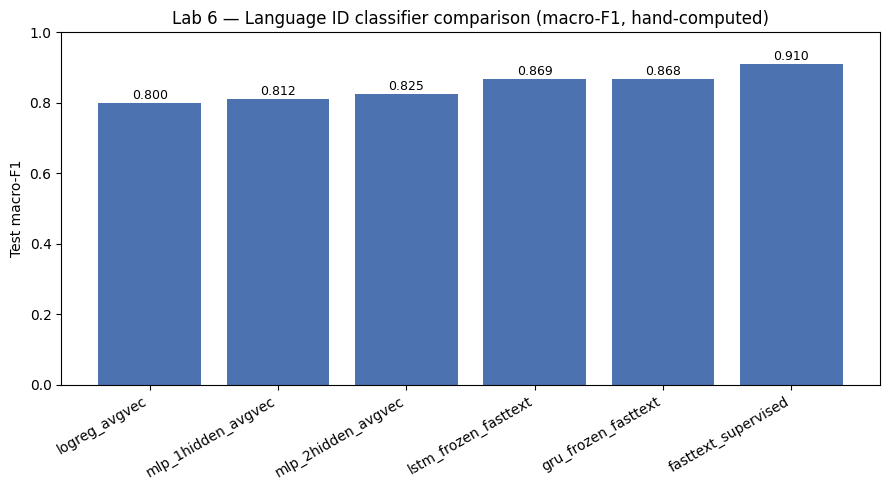

In [17]:
with open(f"{OUT_DIR}/lab6_results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)

fig, ax = plt.subplots(figsize=(9, 5))
vals = [results[n]["test_macro_f1"] for n in order]
bars = ax.bar(range(len(order)), vals, color="#4C72B0")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=30, ha="right")
ax.set_ylabel("Test macro-F1")
ax.set_ylim(0, 1)
ax.set_title("Lab 6 — Language ID classifier comparison (macro-F1, hand-computed)")
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/lab6_comparison.png", dpi=150)
plt.show()


## 9. Where the errors are: script-sharing language clusters

Most of the 23 languages are trivially separable by script alone. The
interesting confusions live inside the script-sharing clusters: 9
Devanagari languages (hin/mar/npi/san/mai/gom/snd/brx/doi), Bengali script
(asm/ben), and Arabic script (kas/urd). Per-class F1 for the best
averaged-vector model and the FastText-supervised model, restricted to
those clusters:

In [18]:
clusters = {
    "Devanagari": ["hin_Deva", "mar_Deva", "npi_Deva", "san_Deva", "mai_Deva",
                   "gom_Deva", "snd_Deva", "brx_Deva", "doi_Deva"],
    "Bengali script": ["asm_Beng", "ben_Beng"],
    "Arabic script": ["kas_Arab", "urd_Arab"],
}

best_avgvec = max(["logreg_avgvec", "mlp_1hidden_avgvec", "mlp_2hidden_avgvec"],
                   key=lambda n: results[n]["test_macro_f1"])
rows = []
for cluster, langs in clusters.items():
    for lang in langs:
        rows.append({
            "cluster": cluster, "language": lang,
            f"{best_avgvec}_f1": results[best_avgvec]["per_class_test"][lang]["f1"],
            "fasttext_supervised_f1": results["fasttext_supervised"]["per_class_test"][lang]["f1"],
            "wiki_vector_coverage_%": coverage[lang]["token_coverage"] * 100,
        })
pd.DataFrame(rows).round(3)


,cluster,language,mlp_2hidden_avgvec_f1,fasttext_supervised_f1,wiki_vector_coverage_%
0,Devanagari,hin_Deva,0.682,0.772,96.131
1,Devanagari,mar_Deva,0.583,0.687,93.985
2,Devanagari,npi_Deva,0.744,0.912,92.474
3,Devanagari,san_Deva,0.729,0.838,91.816
4,Devanagari,mai_Deva,0.597,0.758,92.510
5,Devanagari,gom_Deva,0.459,0.497,93.661
6,Devanagari,snd_Deva,0.995,0.990,92.104
7,Devanagari,brx_Deva,0.824,0.827,95.463
8,Devanagari,doi_Deva,0.650,0.824,95.630
9,Bengali script,asm_Beng,0.990,1.000,87.719


## 10. Discussion

- **`n_hidden=0` MLP ≈ logistic regression, as expected.** Test macro-F1 is
  0.800 (logreg) vs. 0.812 (`n=1`) vs. 0.825 (`n=2`) — a small, monotonic
  gain from added capacity, not a discontinuity, which is the sanity check
  this comparison was meant to provide.

- **"No pretrained wiki vectors" turned out to split into two very
  different outcomes, not one.** Of the 5 languages lacking a
  `wiki.<lang>.vec` file:
  - **Santali and Manipuri (Meitei)** are the real coverage floor — 1.7%
    and 2.7% token coverage against the merged embedding table, because
    they're written in Ol Chiki and Meitei Mayek respectively, scripts that
    share essentially no characters with any of the 18 pretrained
    languages. Averaged-vector logistic regression still gets Santali to
    F1=0.674 (an almost-all-zero feature vector is itself a learnable
    signature), but Manipuri collapses to F1=0.093. The LSTM/GRU recover
    some of this (0.715 / 0.674) since sequence length and the sprinkling
    of covered tokens still carry information a bag-of-means throws away.
  - **Bodo, Dogri, and Khasi do fine anyway** — 87–96% token coverage —
    because Bodo/Dogri are written in Devanagari and Khasi's Wikipedia
    register mixes in enough Latin-script vocabulary that both incidentally
    match tokens from *other* languages' pretrained files (mostly Hindi's,
    since it's processed early into the shared table). Khasi in particular
    reaches F1≈0.94–0.97 on every embedding-based model.
  - **FastText-supervised sidesteps the whole issue** (Santali F1=0.943,
    Manipuri F1=0.964) since it learns its own character n-gram embeddings
    directly from the training text — it doesn't need an external
    vector file to exist at all. This is a real, structural advantage
    for classifier 5, not just a stronger architecture, and it should be
    weighed against the leaderboard in §8 accordingly.

- **The genuinely hard cases are same-script confusions, not OOV.** Bodo
  and Dogri sit at ~95% coverage — as good as Hindi's own — yet score lower
  (LR F1 0.77 / 0.60) than Khasi (0.94) or most other languages, because
  they share both script and a large chunk of vocabulary with
  Hindi/Marathi/Sanskrit. The confusion is semantic/lexical overlap between
  related Devanagari languages, not missing vectors.

- **LSTM/GRU beat averaging by a solid margin here** (macro-F1 ≈0.87 vs.
  ≈0.80–0.83), more than the "word order barely matters for script-level
  language ID" prior would suggest — likely because a recurrent model
  over the token sequence can partially compensate for OOV tokens (it sees
  the whole sequence and unknown-token positions, not just a single
  degraded average), which matters a lot given several languages sit at
  80–90% rather than near-100% coverage.

- **FastText-supervised wins outright** (test macro-F1 = 0.910), consistent
  with it being purpose-built for exactly this kind of short-text
  classification task and immune to the pretrained-vector coverage gap
  that constrains classifiers 1–4.
